# From telescope measurements to two signals: TOI-880

A worked example using **one star, TIC 34077285, in TESS sector 107**. Each flux point measures this star's brightness at a particular time; it does not represent the whole camera's field of view.

This case is useful because the largest signal hides a weaker one. We will reconstruct the benchmark preprocessing, run independent BLS and TLS searches, inspect the warnings, mask the first signal, and search again. **Known planet periods appear only at the end.**

**What you will see:** original flux → quality filtering → gaps and segment edges → estimated slow trend → normalized flux → upward-only clipping → weighted bins and uncertainties → periodograms → individual dips and phase folding → signal masking → second search → catalog comparison.

Run all cells in order using the project's `.venv`. Everything reads local files; no downloads or catalog queries are made. The notebook writes its own figures and a summary under `reports/walkthrough/`; it does not overwrite the benchmark results. The fixed benchmark settings are a starting point, not a validated discovery procedure.

## 1. Load the environment and identify the observation

The star's mass and radius are physical search priors. The detector is not given orbital periods, transit epochs, planet radii, or catalog labels. Locate the project from either its root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, warnings
from importlib.metadata import version
os.environ.setdefault('NUMBA_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from astropy.io import fits
from astropy.timeseries import BoxLeastSquares
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'config/benchmark.json').exists() and (p / 'tess_hunt').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Warning: the tpfmodel submodule.*', category=UserWarning)
    from lightkurve.utils import TessQualityFlags
    from transitleastsquares import period_grid
    from tess_hunt.photometry import preprocess, robust_sigma, odd_window
    from tess_hunt.search import (bls_search, tls_search, conclude, phase_offset,
                                  evaluate_catalog, weighted_mean)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .15,
                     'axes.formatter.useoffset': False})
TIC = 34077285
CONFIG = json.loads((ROOT / 'config/benchmark.json').read_text())
targets = pd.read_csv(ROOT / 'data/benchmark/targets.csv')
target = targets.loc[targets.tic.eq(TIC)].iloc[0]
assert target.sector == 107, 'This walkthrough documents sector 107; selection has changed.'
STELLAR = {'mass': float(target.mass), 'radius': float(target.radius)}
RAW_PATH = ROOT / 'data/raw/benchmark' / target.filename
OUT = ROOT / 'reports/walkthrough'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=140)
    plt.show()
    plt.close(fig)

display(pd.DataFrame([{'star': target.hostname, 'TIC': TIC, 'sector': target.sector,
                       'TESS_magnitude': target.tmag, 'mass_solar': STELLAR['mass'],
                       'radius_solar': STELLAR['radius']}]))
display(pd.Series({p: version(p) for p in ['numpy', 'astropy', 'lightkurve', 'transitleastsquares']}, name='version'))

,star,TIC,sector,TESS_magnitude,mass_solar,radius_solar
0,TOI-880,34077285,107,9.2563,0.87,0.83


numpy                  2.5.4
astropy                8.0.1
lightkurve             2.6.0
transitleastsquares      2.0
Name: version, dtype: object

In [2]:
manifest = json.loads((ROOT / 'data/benchmark/download_manifest.json').read_text())
entry = next(e for e in manifest['files'] if e['tic_id'] == TIC and e['sector'] == 107)
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == entry['sha256'], 'Input file changed.'
with fits.open(RAW_PATH) as hdus:
    header = hdus[1].header
    assert hdus[0].header['TICID'] == TIC and hdus[0].header['SECTOR'] == 107
    info = {'observing_start': header['DATE-OBS'], 'observing_end': header['DATE-END'],
            'time_reference': header['BJDREFI'] + header['BJDREFF'],
            'time_scale': header['TIMESYS'], 'cadence_seconds': header['TIMEDEL'] * 86400,
            'source_URI': entry['source_uri']}
    names = ['TIME', 'SAP_FLUX', 'SAP_FLUX_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR',
             'QUALITY', 'MOM_CENTR1', 'MOM_CENTR2']
    raw = pd.DataFrame({name.lower(): np.asarray(hdus[1].data[name], dtype=int if name == 'QUALITY' else float)
                        for name in names})
display(pd.Series(info, name='FITS metadata'))
display(raw.head())
display(raw.isna().sum().to_frame('missing values'))

observing_start                              2026-08-09T14:24:05.208
observing_end                                2026-09-07T06:30:43.029
time_reference                                             2457000.0
time_scale                                                       TDB
cadence_seconds                                                120.0
source_URI         mast:TESS/product/tess2026221103959-s0107-0000...
Name: FITS metadata, dtype: object

,time,sap_flux,sap_flux_err,pdcsap_flux,pdcsap_flux_err,quality,mom_centr1,mom_centr2
0,4262.082110,NaN,NaN,NaN,NaN,168,NaN,NaN
1,4262.083499,NaN,NaN,NaN,NaN,160,NaN,NaN
2,4262.084888,NaN,NaN,NaN,NaN,32,NaN,NaN
3,4262.086277,NaN,NaN,NaN,NaN,32,NaN,NaN
4,4262.087666,NaN,NaN,NaN,NaN,16,NaN,NaN


,missing values
time,448
sap_flux,475
sap_flux_err,475
pdcsap_flux,5619
pdcsap_flux_err,5619
quality,0
mom_centr1,475
mom_centr2,475


The headers identify observations from **August 9–September 7, 2026**. `TIME` is **BTJD = BJD − 2,457,000**, in TDB days; adding the reference gives a barycentric Julian date, not a Unix timestamp.

`SAP_FLUX` is extracted aperture photometry, in electrons/second. `PDCSAP_FLUX` is the SPOC pipeline's corrected flux. Neither is a raw detector image. `QUALITY` encodes warning bits. A centroid is the estimated position of the star's light on the detector, in pixels.

## 2. Inspect the original measurements

Plot both flux products before our own cleaning. Divide each column by its median **only for this comparison plot**. This rescaling is different from the local detrending performed later. The two panels use their own vertical scales so their structures are visible.

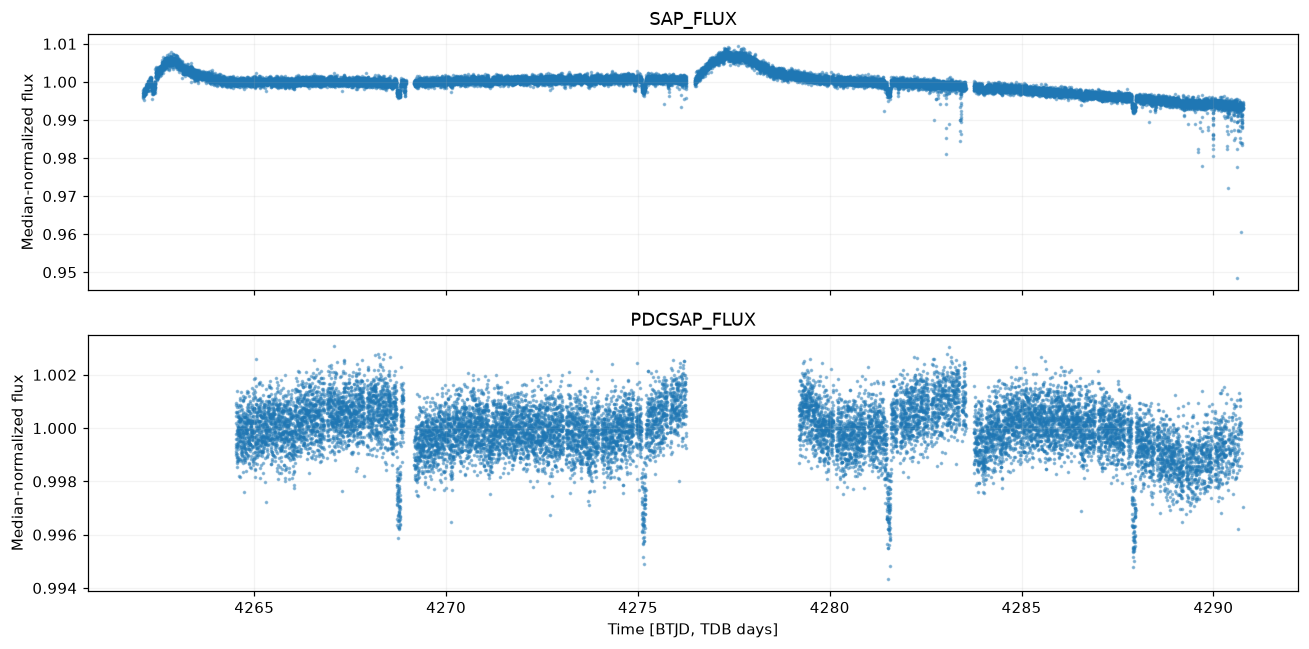

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, name in zip(axes, ['sap_flux', 'pdcsap_flux']):
    ax.scatter(raw.time, raw[name] / raw[name].median(), s=2, alpha=.4)
    ax.set(ylabel='Median-normalized flux', title=name.upper())
axes[-1].set_xlabel('Time [BTJD, TDB days]')
show_figure(fig, '01_original_flux')

Look for slow changes in brightness, excursions, and missing intervals. A gap contains no brightness measurement. A line joining its endpoints would give the misleading impression of continuous coverage.

## 3. Apply the quality and validity filters

Use the same default TESS bitmask as the benchmark. A nonzero `QUALITY` value is not automatically rejected: the bitwise AND selects the warning bits covered by this policy. Require finite time/flux/error and positive corrected flux/error.

The rejection categories can overlap. The final retained count is the combined mask, not the sum of individual rejection counts.

,check,rows
0,Original rows,20656
1,Rejected by quality mask,1927
2,Invalid time/flux/error,5619
3,Retained by both checks,15037


Default quality bitmask: 17087


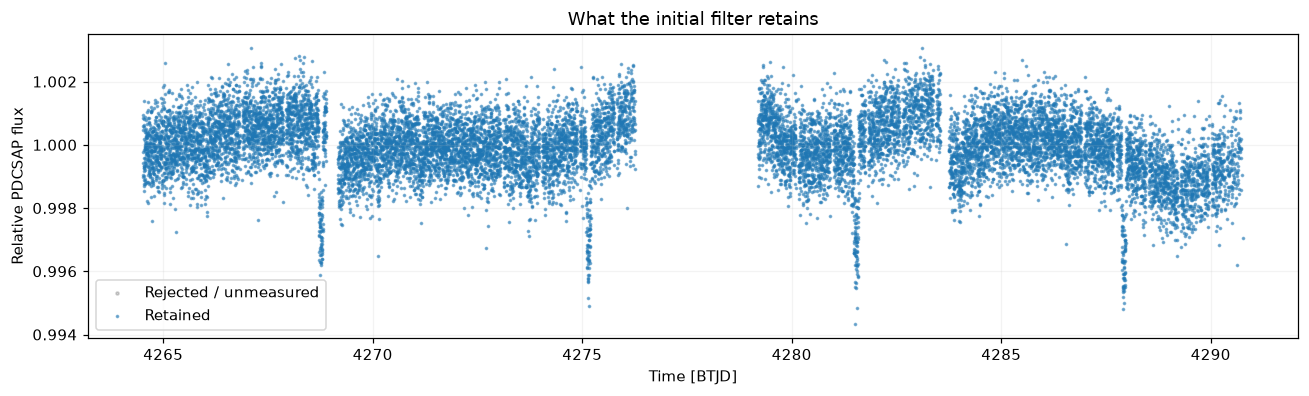

In [4]:
quality_ok = (raw.quality.to_numpy(dtype=int) & TessQualityFlags.DEFAULT_BITMASK) == 0
valid = np.isfinite(raw[['time', 'pdcsap_flux', 'pdcsap_flux_err']]).all(axis=1).to_numpy()
valid &= (raw.pdcsap_flux.to_numpy() > 0) & (raw.pdcsap_flux_err.to_numpy() > 0)
keep = quality_ok & valid
quality_table = pd.DataFrame({
    'check': ['Original rows', 'Rejected by quality mask', 'Invalid time/flux/error', 'Retained by both checks'],
    'rows': [len(raw), int((~quality_ok).sum()), int((~valid).sum()), int(keep.sum())]})
display(quality_table)
print('Default quality bitmask:', TessQualityFlags.DEFAULT_BITMASK)

clean = raw.loc[keep].sort_values('time', kind='stable').drop_duplicates('time').copy()
assert np.all(np.diff(clean.time) > 0)
fig, ax = plt.subplots(figsize=(12, 3.7))
median_flux = raw.pdcsap_flux.median()
ax.scatter(raw.loc[~keep, 'time'], raw.loc[~keep, 'pdcsap_flux'] / median_flux,
           s=4, alpha=.35, color='gray', label='Rejected / unmeasured')
ax.scatter(clean.time, clean.pdcsap_flux / median_flux, s=2, alpha=.5, label='Retained')
ax.set(xlabel='Time [BTJD]', ylabel='Relative PDCSAP flux', title='What the initial filter retains')
ax.legend()
show_figure(fig, '02_quality_filter')

## 4. Keep gaps and treat observing segments separately

Split the retained timestamps wherever the gap exceeds **0.5 days**. Trim **0.1 days from each segment edge** to reduce boundary artifacts. A short segment with fewer than 100 samples is not used.

These values are benchmark choices, not universal astronomical constants. Edge trimming can discard a real transit. The next table makes that loss visible.

In [5]:
t, f, e, c1, c2 = (clean[name].to_numpy(dtype=float) for name in
                    ['time', 'pdcsap_flux', 'pdcsap_flux_err', 'mom_centr1', 'mom_centr2'])
boundaries = np.r_[0, np.flatnonzero(np.diff(t) > CONFIG['split_gap_days']) + 1, len(t)]
segment_rows = []
for number, (start, end) in enumerate(zip(boundaries[:-1], boundaries[1:]), 1):
    st = t[start:end]
    inner = (st >= st[0] + CONFIG['trim_segment_edge_days']) & (st <= st[-1] - CONFIG['trim_segment_edge_days'])
    segment_rows.append({'segment': number, 'start_btjd': st[0], 'end_btjd': st[-1],
                         'span_days': np.ptp(st), 'rows_before_trim': len(st),
                         'rows_after_trim': int(inner.sum()),
                         'usable': bool(len(st) >= 100 and inner.sum() >= 100)})
segments = pd.DataFrame(segment_rows)
display(segments.round(4))
gap_indices = np.flatnonzero(np.diff(t) > CONFIG['split_gap_days'])
display(pd.DataFrame({'gap_start_btjd': t[gap_indices], 'gap_end_btjd': t[gap_indices + 1],
                      'gap_days': np.diff(t)[gap_indices]}).round(4))

,segment,start_btjd,end_btjd,span_days,rows_before_trim,rows_after_trim,usable
0,1,4264.5197,4276.2607,11.7410,7835,7717,True
1,2,4279.1942,4290.7700,11.5758,7202,7110,True


,gap_start_btjd,gap_end_btjd,gap_days
0,4276.2607,4279.1942,2.9335


## 5. Estimate the slow trend and divide it out

For each trimmed segment, estimate a one-day running median $m(t)$. Then transform both flux and uncertainty:

$$ y(t)=\frac{f(t)}{m(t)},\qquad \sigma_y(t)=\frac{\sigma_f(t)}{m(t)}. $$

This treats the estimated trend as fixed; uncertainty in that trend is not propagated. The median is resistant to brief dips, but it can still attenuate long transits or struggle with strong stellar variability. Window size is therefore an important sensitivity choice.

The code below exposes the same steps used by `tess_hunt.photometry.preprocess`. It also retains the trend and intermediate arrays for inspection.

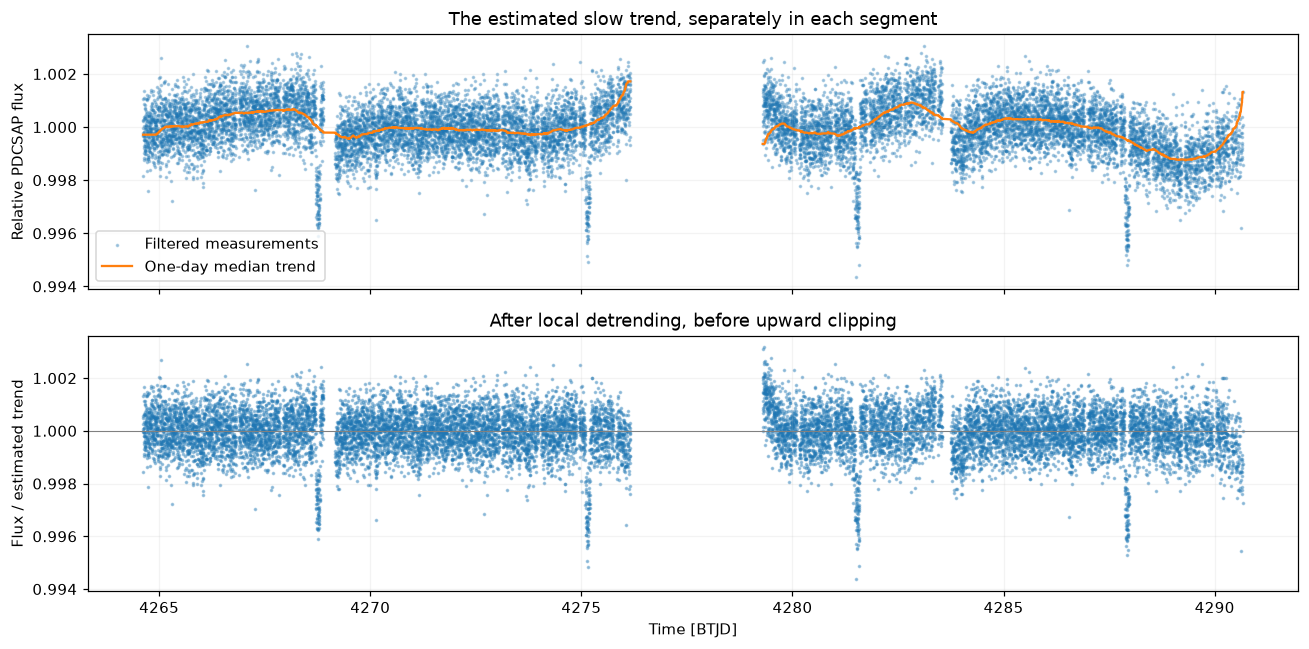

In [6]:
transforms, retained_arrays = [], []
for number, (start, end) in enumerate(zip(boundaries[:-1], boundaries[1:]), 1):
    st, sf, se, sc1, sc2 = (x[start:end].copy() for x in [t, f, e, c1, c2])
    if len(st) < 100:
        continue
    inner = (st >= st[0] + CONFIG['trim_segment_edge_days']) & (st <= st[-1] - CONFIG['trim_segment_edge_days'])
    st, sf, se, sc1, sc2 = (x[inner] for x in [st, sf, se, sc1, sc2])
    if len(st) < 100:
        continue
    width = odd_window(CONFIG['trend_window_days'], np.median(np.diff(st)), len(st))
    trend = median_filter(sf, size=width, mode='nearest')
    normalized, errors = sf / trend, se / trend
    sigma = max(robust_sigma(normalized), float(np.median(errors)))
    accepted = np.isfinite(normalized) & (normalized > 0) & (normalized <= 1 + 8 * sigma)

    # Centroids need their own slow-trend removal for the later motion check.
    residual_centroids = []
    for centroid in [sc1, sc2]:
        finite = np.isfinite(centroid)
        if finite.sum() > 10:
            interpolated = np.interp(st, st[finite], centroid[finite])
            residual = centroid - median_filter(interpolated, size=width, mode='nearest')
        else:
            residual = np.full(len(st), np.nan)
        residual_centroids.append(residual)

    transforms.append({'segment': number, 'time': st, 'flux': sf, 'trend': trend,
                       'normalized': normalized, 'error': errors, 'accepted': accepted,
                       'window_samples': width, 'sigma': sigma})
    retained_arrays.append(np.column_stack([st[accepted], normalized[accepted], errors[accepted],
                                            sc1[accepted], sc2[accepted],
                                            residual_centroids[0][accepted], residual_centroids[1][accepted]]))
unbinned = np.concatenate(retained_arrays)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for index, part in enumerate(transforms):
    axes[0].scatter(part['time'], part['flux'] / median_flux, s=2, alpha=.3,
                    color='tab:blue', label='Filtered measurements' if index == 0 else None)
    axes[0].plot(part['time'], part['trend'] / median_flux, color='tab:orange', lw=1.5,
                 label='One-day median trend' if index == 0 else None)
    axes[1].scatter(part['time'], part['normalized'], s=2, alpha=.35, color='tab:blue')
axes[0].set(ylabel='Relative PDCSAP flux', title='The estimated slow trend, separately in each segment')
axes[0].legend()
axes[1].set(xlabel='Time [BTJD]', ylabel='Flux / estimated trend', title='After local detrending, before upward clipping')
axes[1].axhline(1, color='gray', lw=.7)
show_figure(fig, '03_detrending')

## 6. Remove large upward excursions; retain downward dips

The benchmark removes values above `1 + 8 × sigma`, where sigma is the larger of robust flux scatter and median reported uncertainty. It does **not** symmetrically sigma-clip: a sufficiently deep downward excursion could be the phenomenon we are looking for.

This is not an artifact classifier. Downward instrumental excursions can survive and must be assessed during signal vetting.

In [7]:
clip_rows = []
for part in transforms:
    clip_rows.append({'segment': part['segment'], 'median_window_samples': part['window_samples'],
                      'robust_or_formal_sigma_ppm': part['sigma'] * 1e6,
                      'rows_after_edge_trim': len(part['time']),
                      'upward_or_invalid_rows_removed': int((~part['accepted']).sum()),
                      'rows_retained': int(part['accepted'].sum())})
display(pd.DataFrame(clip_rows).round(2))
print(f'Detrended, retained two-minute samples: {len(unbinned):,}')

,segment,median_window_samples,robust_or_formal_sigma_ppm,rows_after_edge_trim,upward_or_invalid_rows_removed,rows_retained
0,1,721,757.17,7717,0,7717
1,2,721,787.52,7110,0,7110


Detrended, retained two-minute samples: 14,827


## 7. Make ten-minute weighted bins and scale uncertainties

Within each fixed time bin, use inverse-variance weights $w_i=1/\sigma_i^2$:

$$ \bar y = \frac{\sum_i w_i y_i}{\sum_i w_i},\qquad
\sigma_{\bar y} = \frac{1}{\sqrt{\sum_i w_i}}. $$

The timestamp is weighted in the same way. Bins containing fewer than two observed samples are dropped. Empty bins stay empty; gaps are never interpolated.

The formal error formula assumes independent samples. As a first correction, the pipeline compares adjacent-bin scatter with median formal error and scales errors upward if needed. The later vetting step separately estimates noise on a transit-duration timescale. Neither correction fully models correlated stellar or instrumental noise.

In [8]:
labels = np.floor((unbinned[:, 0] - unbinned[0, 0]) / (CONFIG['bin_minutes'] / 1440)).astype(int)
binned_rows, bin_details = [], []
for label in np.unique(labels):
    points = unbinned[labels == label]
    if len(points) < 2:
        continue
    weights = 1 / points[:, 2] ** 2
    row = [np.average(points[:, 0], weights=weights),
           np.average(points[:, 1], weights=weights), 1 / np.sqrt(weights.sum())]
    row.extend(float(np.nanmean(points[:, j])) if np.isfinite(points[:, j]).any() else np.nan for j in [5, 6])
    binned_rows.append(row)
    bin_details.append({'bin': int(label), 'original_samples': len(points),
                        'time_btjd': row[0], 'weighted_flux': row[1], 'formal_error': row[2]})
binned = np.asarray(binned_rows)
bt, by, formal_error, bc1, bc2 = binned.T
adjacent = np.diff(bt) < 1.5 * CONFIG['bin_minutes'] / 1440
point_scatter = robust_sigma(np.diff(by)[adjacent]) / np.sqrt(2)
error_scale = max(1.0, point_scatter / np.median(formal_error))
scaled_error = formal_error * error_scale
DATA = {'time': bt, 'flux': by, 'error': scaled_error, 'centroid1': bc1, 'centroid2': bc2}
display(pd.DataFrame(bin_details).head(8))
display(pd.Series({'search_bins': len(bt), 'adjacent_bin_scatter_ppm': point_scatter * 1e6,
                   'median_formal_bin_error_ppm': np.median(formal_error) * 1e6,
                   'error_scale_factor': error_scale,
                   'median_scaled_bin_error_ppm': np.median(scaled_error) * 1e6}, name='Binning diagnostics'))

,bin,original_samples,time_btjd,weighted_flux,formal_error
0,0,5,4264.622516,1.000165,0.000343
1,1,5,4264.629461,0.999841,0.000343
2,2,5,4264.636406,1.000719,0.000343
3,3,5,4264.643350,1.000247,0.000343
4,4,5,4264.650295,0.999657,0.000343
5,5,5,4264.657240,0.999901,0.000343
6,6,5,4264.664184,1.000704,0.000343
7,7,5,4264.671129,0.999924,0.000343


search_bins                    3070.000000
adjacent_bin_scatter_ppm        335.082697
median_formal_bin_error_ppm     326.731164
error_scale_factor                1.025561
median_scaled_bin_error_ppm     335.082697
Name: Binning diagnostics, dtype: float64

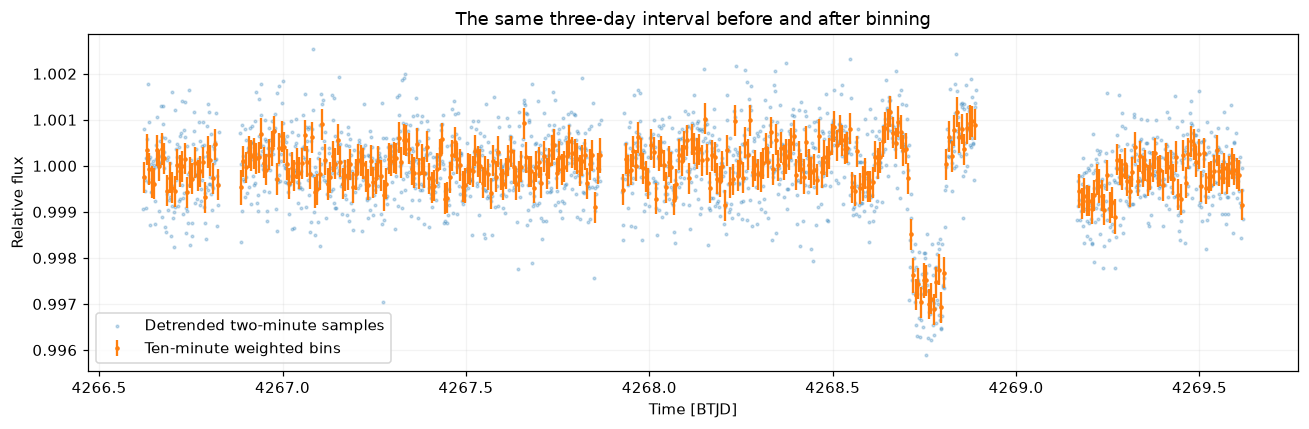

In [9]:
longest = max(transforms, key=lambda p: np.ptp(p['time']))
zoom_start = longest['time'].min() + 2
zoom_end = zoom_start + 3
u = (unbinned[:, 0] >= zoom_start) & (unbinned[:, 0] <= zoom_end)
b = (bt >= zoom_start) & (bt <= zoom_end)
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(unbinned[u, 0], unbinned[u, 1], s=3, alpha=.25, label='Detrended two-minute samples')
ax.errorbar(bt[b], by[b], yerr=scaled_error[b], fmt='.', color='tab:orange', ms=4,
             label='Ten-minute weighted bins')
ax.set(xlabel='Time [BTJD]', ylabel='Relative flux', title='The same three-day interval before and after binning')
ax.legend()
show_figure(fig, '04_binning_zoom')

## 8. Verify that the walkthrough reproduces production preprocessing

The preceding transformations were exposed for learning. Now call the production function independently and compare its arrays with ours. This prevents a visually convincing walkthrough from quietly using a different preprocessing recipe.

In [10]:
production_data, preprocessing = preprocess(RAW_PATH, CONFIG)
for key in DATA:
    np.testing.assert_allclose(DATA[key], production_data[key], rtol=1e-12, atol=1e-12, equal_nan=True)
np.testing.assert_allclose(unbinned[:, 0], production_data['unbinned_time'])
np.testing.assert_allclose(unbinned[:, 1], production_data['unbinned_flux'])
np.testing.assert_allclose(unbinned[:, 2], production_data['unbinned_error'])
print('All reconstructed preprocessing arrays match the production pipeline.')
display(pd.DataFrame({'stage': ['Original FITS rows', 'Quality + validity filter',
                               'Segment trimming + detrending + upward clipping', 'Weighted search bins'],
                      'rows': [len(raw), len(clean), len(unbinned), len(bt)]}))

All reconstructed preprocessing arrays match the production pipeline.


,stage,rows
0,Original FITS rows,20656
1,Quality + validity filter,15037
2,Segment trimming + detrending + upward clipping,14827
3,Weighted search bins,3070


## 9. Search a broad period range with BLS

Box Least Squares tests repeated box-shaped dips. For each trial period, it varies the dip duration and time offset and measures improvement over constant brightness. This is a transit search rather than an FFT of a sinusoid.

The trial grid uses stellar mass/radius and observing span, not a known orbital period. The upper bound is the smaller of 12 days and half the usable span. Here we explicitly construct the grid, fit all the boxes, and show the intermediate likelihood powers. The production helper adds scores, alternative peaks and common vetting.

In [11]:
period_max = min(CONFIG['period_max_days'], np.ptp(bt) / CONFIG['minimum_observed_transits'])
with warnings.catch_warnings(record=True) as grid_warnings:
    periods = np.sort(period_grid(R_star=STELLAR['radius'], M_star=STELLAR['mass'],
                                  time_span=np.ptp(bt), period_min=CONFIG['period_min_days'],
                                  period_max=period_max, oversampling_factor=CONFIG['tls_oversampling'],
                                  n_transits_min=2))
durations = np.geomspace(CONFIG['duration_min_days'], CONFIG['duration_max_days'], 14)
box_model = BoxLeastSquares(bt, by, scaled_error)
box_result = box_model.power(periods, durations, objective='likelihood', oversample=10)
manual_bls_score = (box_result.power - np.median(box_result.power)) / max(robust_sigma(box_result.power), 1e-12)
bls1, bls_spectrum1 = bls_search(DATA, STELLAR, CONFIG)
np.testing.assert_allclose(manual_bls_score, bls_spectrum1['score'])
display(pd.Series({'minimum_trial_period_days': periods.min(), 'maximum_trial_period_days': periods.max(),
                   'trial_periods': len(periods), 'trial_durations_hours': np.round(durations * 24, 3)}, name='BLS search grid'))
display(pd.DataFrame([{k: peak[k] for k in ['period', 'epoch_btjd', 'duration_days', 'sde', 'model_depth']}
                      for peak in bls1['peaks']]).round(6))

minimum_trial_period_days                                             0.500117
maximum_trial_period_days                                            11.992129
trial_periods                                                             2934
trial_durations_hours        [0.6, 0.726, 0.879, 1.065, 1.289, 1.56, 1.889,...
Name: BLS search grid, dtype: object

,period,epoch_btjd,duration_days,sde,model_depth
0,6.385487,4268.760016,0.095,23.487832,0.002932
1,3.194055,4265.567516,0.095,12.311718,0.001659
2,9.580576,4268.757516,0.095,10.220217,0.002792


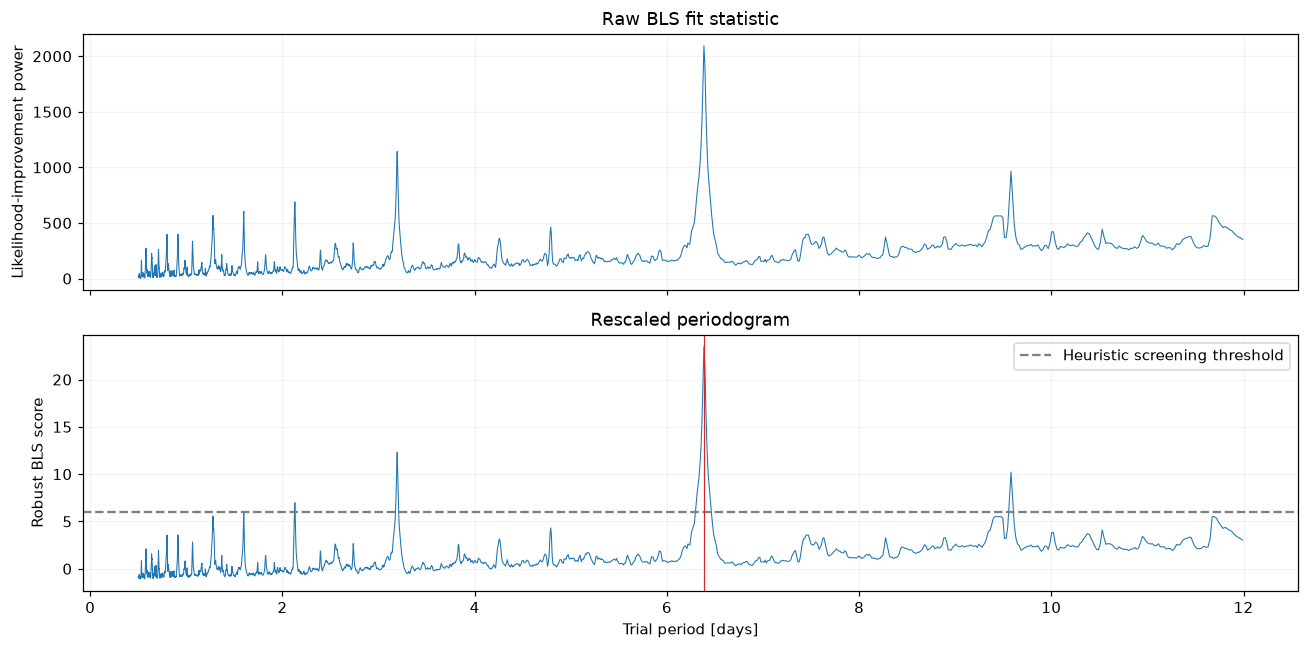

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(periods, box_result.power, lw=.7)
axes[0].set(ylabel='Likelihood-improvement power', title='Raw BLS fit statistic')
axes[1].plot(periods, manual_bls_score, lw=.7)
axes[1].axhline(CONFIG['bls_min_sde'], color='gray', ls='--', label='Heuristic screening threshold')
axes[1].axvline(bls1['best']['period'], color='tab:red', lw=.8)
axes[1].set(xlabel='Trial period [days]', ylabel='Robust BLS score', title='Rescaled periodogram')
axes[1].legend()
show_figure(fig, '05_bls_intermediate')

The benchmark's BLS score is `(power − median power) / (1.4826 × MAD power)`. It is a heuristic periodogram normalization. It is **not the same statistic as TLS SDE**, and its threshold is not a calibrated false-alarm probability.

The alternative BLS peaks are useful: half or double the leading period can align subsets of the same events. A large peak alone does not establish that it represents another planet.

## 10. Independently search with TLS

Transit Least Squares uses shaped transit templates instead of flat boxes. It searches the full allowed period range independently; it does not refine a period supplied by BLS. The helper in `tess_hunt/search.py` records its best fit and runs the same common vetting.

The physical priors allow ±20% ranges around the cataloged stellar mass/radius. The fixed quadratic limb-darkening coefficients `[0.3, 0.2]` are generic, not a fitted atmosphere model. TLS 2.0 uses the `fused-pl` backend with one thread.

period_min_days                       0.5
period_max_days                      12.0
stellar_mass_solar                   0.87
stellar_radius_solar                 0.83
stellar_prior_fraction                0.2
oversampling                            3
duration_grid_step                    1.1
limb_darkening_coefficients    [0.3, 0.2]
backend                          fused-pl
Name: TLS settings, dtype: object

,TLS library messages
0,period_grid defaults to R_star=1 and M_star=1 ...


,period,sde
0,6.385487,23.302359
1,3.194055,8.308713
2,9.580576,4.904950


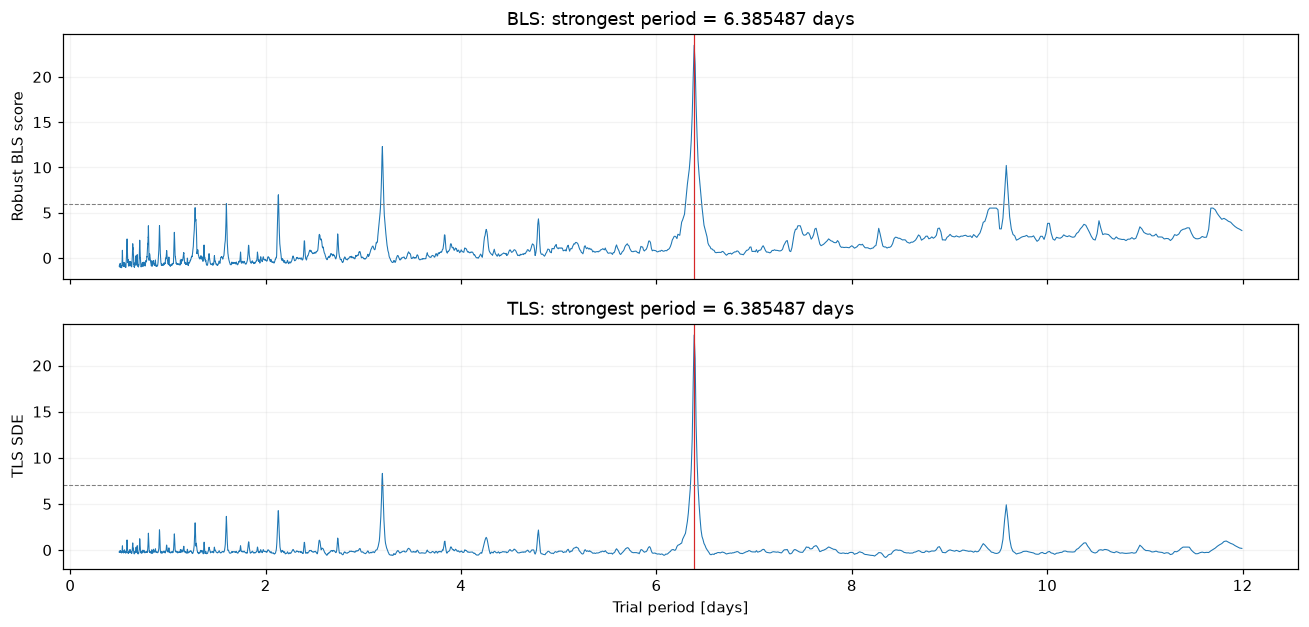

In [13]:
display(pd.Series({'period_min_days': CONFIG['period_min_days'], 'period_max_days': period_max,
                   'stellar_mass_solar': STELLAR['mass'], 'stellar_radius_solar': STELLAR['radius'],
                   'stellar_prior_fraction': .20, 'oversampling': CONFIG['tls_oversampling'],
                   'duration_grid_step': CONFIG['tls_duration_grid_step'],
                   'limb_darkening_coefficients': [0.3, 0.2], 'backend': 'fused-pl'}, name='TLS settings'))
with warnings.catch_warnings(record=True) as tls_warnings1:
    warnings.simplefilter('always')
    tls1, tls_spectrum1 = tls_search(DATA, STELLAR, CONFIG)
if tls_warnings1:
    display(pd.DataFrame({'TLS library messages': sorted(set(str(w.message) for w in tls_warnings1))}))
display(pd.DataFrame(tls1['peaks']).round(6))

def plot_periodograms(bls, bs, tls, ts, name):
    fig, axes = plt.subplots(2, 1, figsize=(12, 5.8), sharex=True)
    for ax, result, spectrum, power_key, threshold in [
        (axes[0], bls, bs, 'score', CONFIG['bls_min_sde']),
        (axes[1], tls, ts, 'power', CONFIG['tls_min_sde'])]:
        ax.plot(spectrum['periods'], spectrum[power_key], lw=.7)
        ax.axvline(result['best']['period'], color='tab:red', lw=.8)
        ax.axhline(threshold, color='gray', ls='--', lw=.7)
        ax.set(ylabel='Robust BLS score' if result['method'] == 'BLS' else 'TLS SDE',
               title=f"{result['method']}: strongest period = {result['best']['period']:.6f} days")
    axes[-1].set_xlabel('Trial period [days]')
    show_figure(fig, name)

plot_periodograms(bls1, bls_spectrum1, tls1, tls_spectrum1, '06_first_search')

## 11. Fold the data and inspect individual events

For a candidate period $P$ and epoch $t_0$, map every timestamp to its offset from the nearest predicted transit:

$$ \Delta t = ((t-t_0+P/2)\bmod P)-P/2. $$

This overlays different events on one plot. Repeated dips add coherently while much of the noise averages down. Folding can also make an artifact look convincing, so inspect the individual events as well.

The orange points below are weighted **display bins in phase**, distinct from the ten-minute time bins used by the detector. The red line is the fitted box or TLS visualization template; it is not an independent measurement.

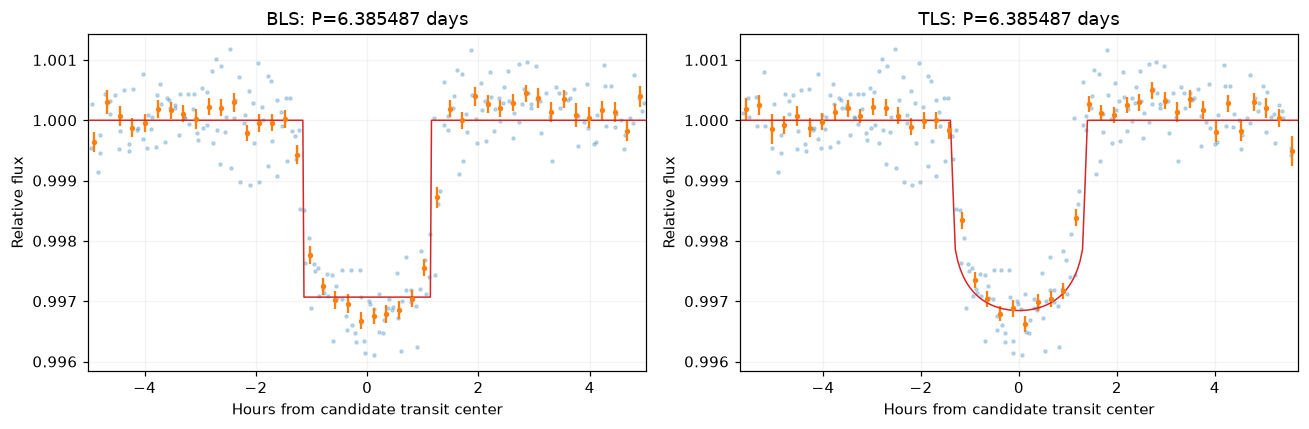

,cycle,epoch_btjd,points,depth,depth_error,snr
0,0,4268.762992,15,0.002937,0.000130,22.521552
1,1,4275.148479,16,0.003456,0.000129,26.796512
2,2,4281.533966,15,0.003200,0.000126,25.339050
3,3,4287.919453,16,0.003494,0.000123,28.451578


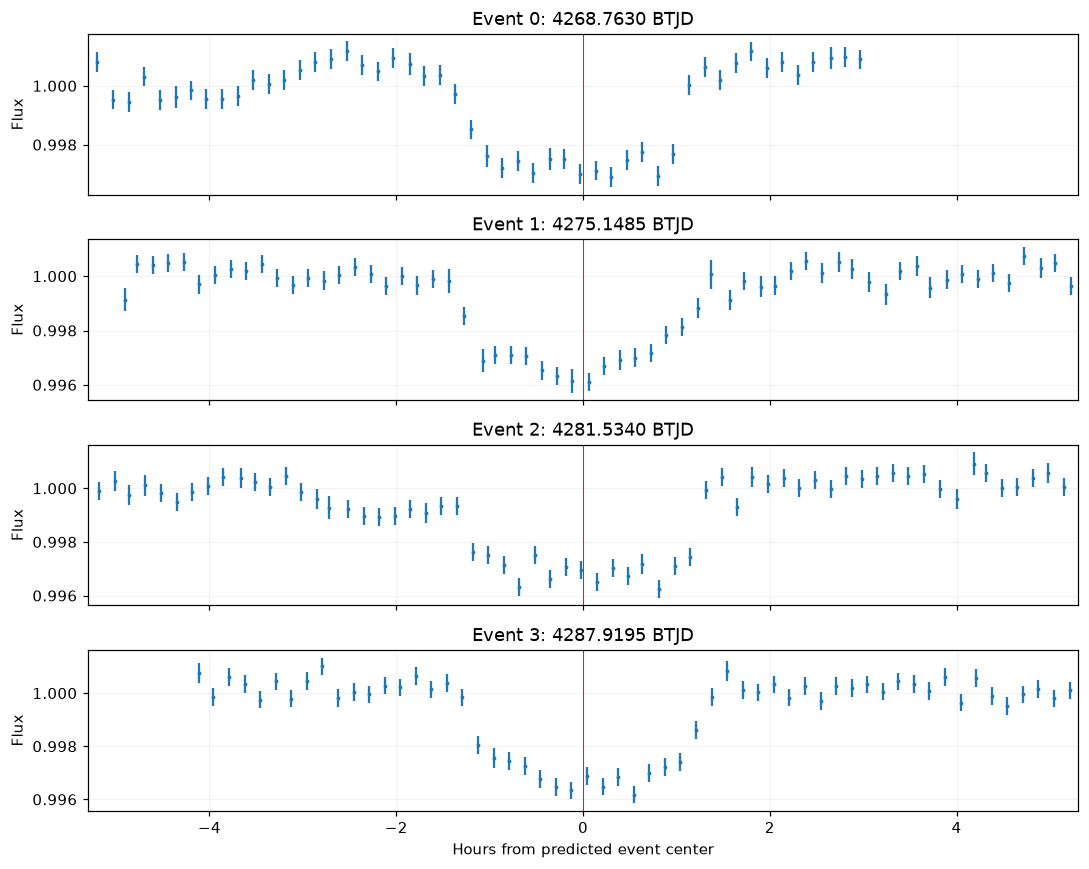

In [14]:
def plot_folded_pair(data, bls, tls, tls_spectrum, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, method in zip(axes, [bls, tls]):
        best = method['best']
        period, epoch, duration = best['period'], best['epoch_btjd'], best['duration_days']
        offset = phase_offset(data['time'], period, epoch)
        half_width = min(period / 2, max(.18, 2.2 * duration))
        near = abs(offset) < half_width
        ax.scatter(offset[near] * 24, data['flux'][near], s=4, alpha=.25)
        centers, means, errors = [], [], []
        edges = np.linspace(-half_width, half_width, 45)
        for low, high in zip(edges[:-1], edges[1:]):
            mask = (offset >= low) & (offset < high)
            if mask.any():
                mean, error = weighted_mean(data['flux'][mask], data['error'][mask])
                centers.append((low + high) * 12); means.append(mean); errors.append(error)
        ax.errorbar(centers, means, yerr=errors, fmt='.', color='tab:orange', ms=5)
        if method['method'] == 'TLS':
            ax.plot((tls_spectrum['model_phase'] - .5) * period * 24,
                    tls_spectrum['model_flux'], color='tab:red', lw=1)
        else:
            grid = np.linspace(-half_width, half_width, 500)
            model = 1 - best['model_depth'] * (abs(grid) < duration / 2)
            ax.plot(grid * 24, model, color='tab:red', lw=1)
        ax.set(xlim=(-half_width * 24, half_width * 24), xlabel='Hours from candidate transit center',
               ylabel='Relative flux', title=f"{method['method']}: P={period:.6f} days")
    show_figure(fig, name)

plot_folded_pair(DATA, bls1, tls1, tls_spectrum1, '07_first_signal_folded')
events1 = pd.DataFrame(tls1['best']['vetting']['events'])
display(events1[['cycle', 'epoch_btjd', 'points', 'depth', 'depth_error', 'snr']].round(6))
fig, axes = plt.subplots(len(events1), 1, figsize=(10, 2 * len(events1)), sharex=True)
for ax, event in zip(np.atleast_1d(axes), events1.to_dict('records')):
    local = abs(bt - event['epoch_btjd']) < .22
    ax.errorbar((bt[local] - event['epoch_btjd']) * 24, by[local], yerr=scaled_error[local], fmt='.', ms=3)
    ax.axvline(0, color='tab:red', lw=.7)
    ax.set(ylabel='Flux', title=f"Event {event['cycle']}: {event['epoch_btjd']:.4f} BTJD", xlim=(-5.3, 5.3))
axes[-1].set_xlabel('Hours from predicted event center')
show_figure(fig, '08_individual_events')

## 12. Vet the signal before assigning a conclusion

The common checks count **observed** events, not all events mathematically predicted inside the baseline. Local references estimate each event's depth; odd/even comparisons use its central half to reduce ingress sampling differences.

`pink_snr` estimates depth significance using out-of-transit averages on a transit-duration timescale. Centroid significance also includes a correction based on duration-scale motion. Both are approximations. A warning means investigate, not automatically reject the signal as a planet or declare it an eclipsing binary.

In [15]:
def method_table(methods):
    rows = []
    for signal_number, method in methods:
        best, vet = method['best'], method['best']['vetting']
        rows.append({'signal': signal_number, 'method': method['method'], 'period_days': best['period'],
                     'duration_hours': best['duration_days'] * 24, 'depth_ppm': vet['depth_ppm'],
                     'periodogram_score': best['sde'], 'duration_scale_SNR': vet['pink_snr'],
                     'observed_events': vet['observed_transits'], 'odd_even_sigma': vet['odd_even_sigma'],
                     'centroid_sigma': vet['centroid_snr'], 'flags': ', '.join(vet['flags']) or 'none'})
    return pd.DataFrame(rows)

decision1 = conclude(bls1, tls1, CONFIG)
display(method_table([(1, bls1), (1, tls1)]).round(4))
display(pd.Series({'BLS_score_threshold': CONFIG['bls_min_sde'], 'TLS_SDE_threshold': CONFIG['tls_min_sde'],
                   'duration_scale_SNR_threshold': CONFIG['minimum_depth_snr'],
                   'minimum_observed_events': CONFIG['minimum_observed_transits'],
                   'period_agreement_tolerance_fraction': CONFIG['period_agreement_fraction']}, name='Screening thresholds'))
display(Markdown(f"**First-signal conclusion:** `{decision1['conclusion']}`. {decision1['reason']}"))
display(Markdown(f"**Warnings:** {', '.join(decision1['flags']) or 'none'}."))

,signal,method,period_days,duration_hours,depth_ppm,periodogram_score,duration_scale_SNR,observed_events,odd_even_sigma,centroid_sigma,flags
0,1,BLS,6.3855,2.2800,2934.0188,23.4878,37.6952,4,2.5162,5.2290,centroid_shift_requires_pixel_review
1,1,TLS,6.3855,2.5896,2757.4051,23.3024,39.6313,4,3.1740,5.2969,"odd_even_depth_mismatch, centroid_shift_requir..."


BLS_score_threshold                    6.00
TLS_SDE_threshold                      7.00
duration_scale_SNR_threshold           7.10
minimum_observed_events                2.00
period_agreement_tolerance_fraction    0.01
Name: Screening thresholds, dtype: float64

**First-signal conclusion:** `signal_requires_review`. At least one method passes the screening thresholds; agreement or false-positive checks require review.

**Warnings:** centroid_shift_requires_pixel_review, odd_even_depth_mismatch.

The first period agrees between methods and the events are strong, but the depth/motion checks require review. The benchmark's final warning list follows the preferred method's window, so inspect the individual method rows as well.

## 13. Mask the first signal and search the remaining observations

A strong detected signal can obscure a weaker one. Exclude its predicted windows, using the **detected** period, epoch and duration. The mask extends to ±0.75 times the detected duration: a total window width of 1.5 transit durations.

This deletes samples; it does not subtract a model or fill the new gaps. We mask when either method passes the basic signal thresholds, even if the first signal needs review. If the first detection is an artifact, masking can discard useful data—another reason to inspect it.

bins_before_mask    3070.000000
bins_removed          93.000000
bins_remaining      2977.000000
removed_percent        3.029316
Name: First-signal mask, dtype: float64

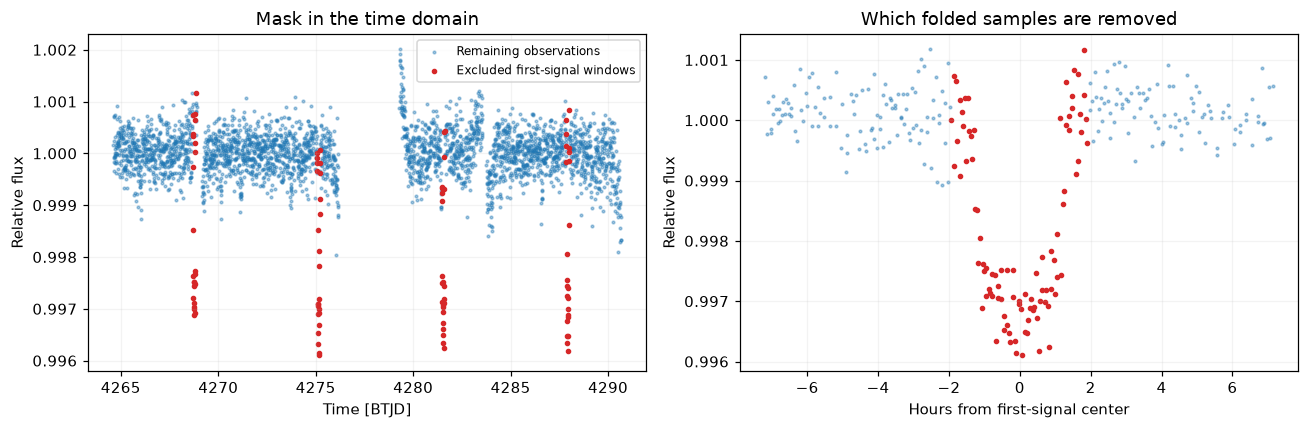

In [16]:
assert decision1['bls_supported'] or decision1['tls_supported'], 'No supported leading signal to mask.'
offset1 = phase_offset(bt, decision1['candidate_period'], decision1['candidate_epoch_btjd'])
residual_keep = abs(offset1) > .75 * decision1['candidate_duration_days']
RESIDUAL = {name: values[residual_keep] for name, values in DATA.items()}
display(pd.Series({'bins_before_mask': len(bt), 'bins_removed': int((~residual_keep).sum()),
                   'bins_remaining': int(residual_keep.sum()),
                   'removed_percent': 100 * (~residual_keep).mean()}, name='First-signal mask'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(bt[residual_keep], by[residual_keep], s=3, alpha=.4, label='Remaining observations')
axes[0].scatter(bt[~residual_keep], by[~residual_keep], s=7, color='tab:red', label='Excluded first-signal windows')
axes[0].set(xlabel='Time [BTJD]', ylabel='Relative flux', title='Mask in the time domain')
axes[0].legend(fontsize=8)
near = abs(offset1) < .3
axes[1].scatter(offset1[near & residual_keep] * 24, by[near & residual_keep], s=3, alpha=.4)
axes[1].scatter(offset1[near & ~residual_keep] * 24, by[near & ~residual_keep], s=7, color='tab:red')
axes[1].set(xlabel='Hours from first-signal center', ylabel='Relative flux', title='Which folded samples are removed')
show_figure(fig, '09_mask_first_signal')

## 14. Run both searches again, over the full range

The residual search receives the same stellar priors and search settings. We do not supply the expected period of the weaker signal. A second peak can now become the leading result because the strongest events have been excluded.

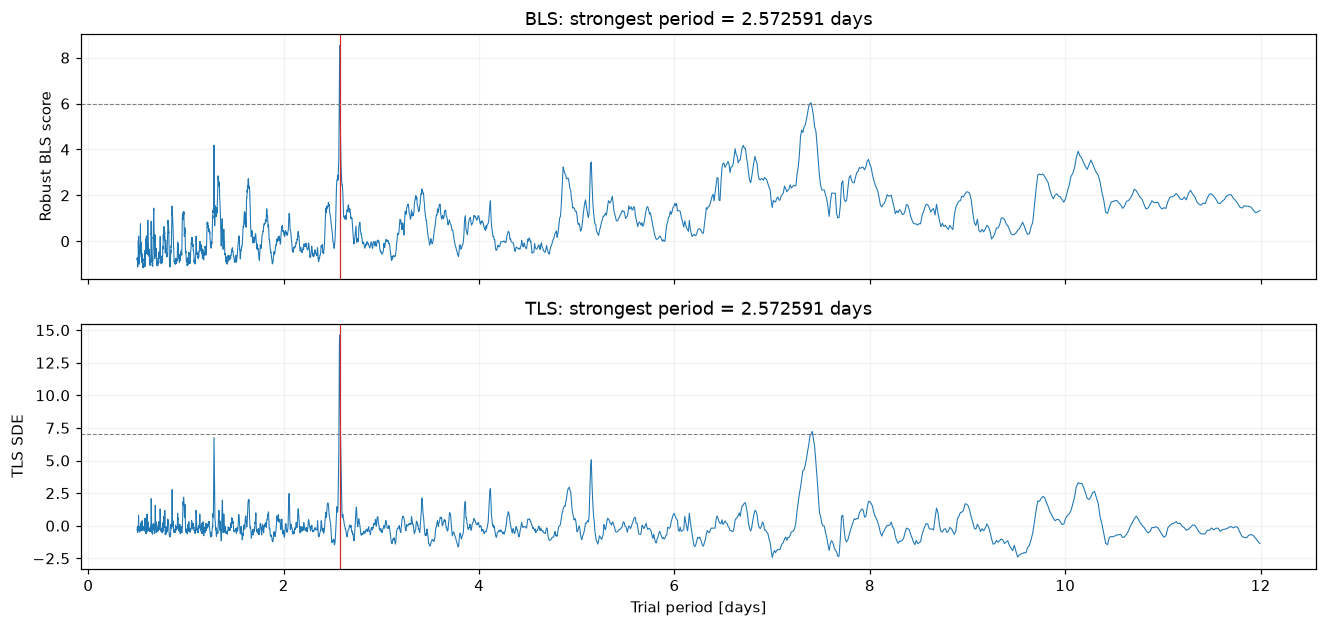

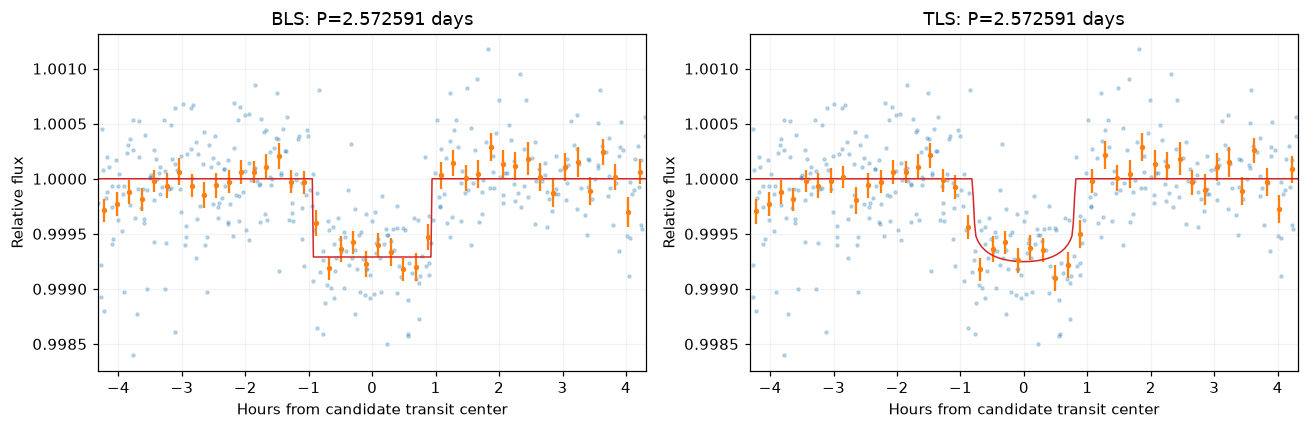

,signal,method,period_days,duration_hours,depth_ppm,periodogram_score,duration_scale_SNR,observed_events,odd_even_sigma,centroid_sigma,flags
0,1,BLS,6.3855,2.2800,2934.0188,23.4878,37.6952,4,2.5162,5.2290,centroid_shift_requires_pixel_review
1,1,TLS,6.3855,2.5896,2757.4051,23.3024,39.6313,4,3.1740,5.2969,"odd_even_depth_mismatch, centroid_shift_requir..."
2,2,BLS,2.5726,1.8600,709.5767,8.5400,13.8512,8,1.0517,2.5499,none
3,2,TLS,2.5726,1.4706,724.2147,14.6217,13.5013,8,1.0424,2.4997,none


**Second-signal conclusion:** `supported_transit_like_signal`. Independent BLS/TLS searches agree in period and phase; repeat-event and common vetting checks pass.

In [17]:
bls2, bls_spectrum2 = bls_search(RESIDUAL, STELLAR, CONFIG)
with warnings.catch_warnings(record=True) as tls_warnings2:
    warnings.simplefilter('always')
    tls2, tls_spectrum2 = tls_search(RESIDUAL, STELLAR, CONFIG)
if tls_warnings2:
    display(pd.DataFrame({'TLS library messages': sorted(set(str(w.message) for w in tls_warnings2))}))
decision2 = conclude(bls2, tls2, CONFIG)
plot_periodograms(bls2, bls_spectrum2, tls2, tls_spectrum2, '10_residual_search')
plot_folded_pair(RESIDUAL, bls2, tls2, tls_spectrum2, '11_second_signal_folded')
display(method_table([(1, bls1), (1, tls1), (2, bls2), (2, tls2)]).round(4))
display(Markdown(f"**Second-signal conclusion:** `{decision2['conclusion']}`. {decision2['reason']}"))

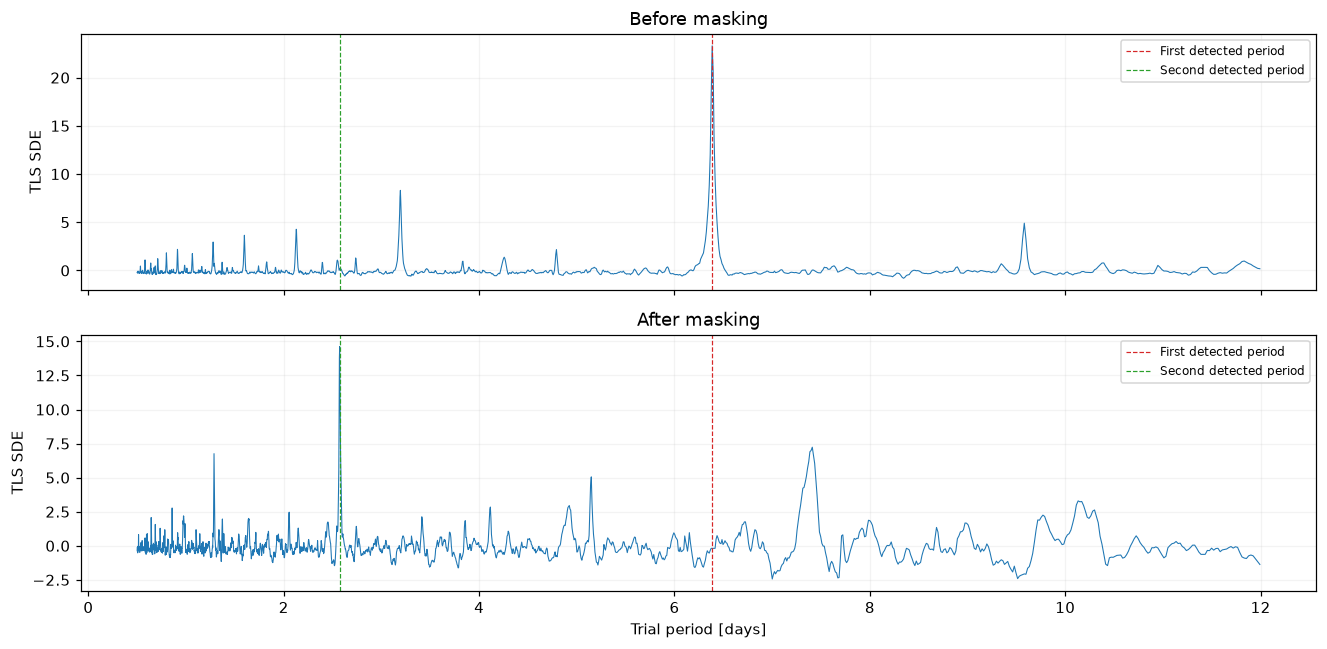

,cycle,epoch_btjd,points,depth,depth_error,snr
0,0,4266.009087,9,0.000523,0.000174,3.004764
1,1,4268.581678,9,0.000517,0.000159,3.247300
2,2,4271.154269,8,0.000763,0.000171,4.466908
3,3,4273.726860,9,0.000763,0.000157,4.870595
4,6,4281.444632,6,0.001193,0.000198,6.033496
5,7,4284.017223,9,0.000868,0.000170,5.106660
6,8,4286.589814,9,0.000745,0.000169,4.407221
7,9,4289.162405,9,0.000470,0.000174,2.707790


In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, spectrum, label in [(axes[0], tls_spectrum1, 'Before masking'),
                             (axes[1], tls_spectrum2, 'After masking')]:
    ax.plot(spectrum['periods'], spectrum['power'], lw=.7)
    ax.axvline(tls1['best']['period'], color='tab:red', ls='--', lw=.8, label='First detected period')
    ax.axvline(tls2['best']['period'], color='tab:green', ls='--', lw=.8, label='Second detected period')
    ax.set(ylabel='TLS SDE', title=label)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('Trial period [days]')
show_figure(fig, '12_before_after_periodograms')
display(pd.DataFrame(tls2['best']['vetting']['events'])[['cycle', 'epoch_btjd', 'points', 'depth', 'depth_error', 'snr']].round(6))

The two curves have been normalized using their own noise backgrounds, so compare the **locations and prominence** of their peaks rather than interpreting their height ratio as a physical brightness change.

The second signal is shallower and has more observed events. Its depth and motion checks pass the benchmark screening. Passing these checks still does not confirm a planet.

## 15. Reveal the catalog only after the searches

Now read the known-planet table. Compare the independently recovered periods with the saved catalog snapshot. A match within the benchmark's 1% period tolerance is a **period match**, not a full orbital fit or a discovery.

Catalog epochs can drift over time, and this benchmark does not propagate period/epoch uncertainties or standardize all published time scales. Epoch offsets remain diagnostics rather than confirmation tests.

In [19]:
known = pd.read_csv(ROOT / 'data/benchmark/known_planets.csv')
known = known.loc[known.tic.eq(TIC)].copy()
display(known[['pl_name', 'tran_flag', 'pl_orbper', 'pl_rade', 'pl_trandur', 'discoverymethod']]
        .rename(columns={'pl_name': 'catalog_name', 'pl_orbper': 'period_days',
                         'pl_rade': 'radius_Earth', 'pl_trandur': 'duration_hours'}))
signals = [{'iteration': 1, 'bls': bls1, 'tls': tls1, 'decision': decision1},
           {'iteration': 2, 'bls': bls2, 'tls': tls2, 'decision': decision2}]
evaluation = evaluate_catalog(signals, known.to_dict('records'), CONFIG)
comparison_rows = []
for planet in evaluation:
    for match in planet['matches']:
        comparison_rows.append({'catalog_planet': planet['planet'], 'catalog_period_days': planet['catalog_period_days'],
                                'signal': match['iteration'], 'method': match['method'],
                                'recovered_period_days': match['period'],
                                'period_difference_percent': 100 * (match['period'] / planet['catalog_period_days'] - 1),
                                'match_type': match['relation'], 'passes_basic_screening': match['supported'],
                                'catalog_epoch_offset_days': match['epoch_offset_days']})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))
assert all(planet['supported_exact_period_match'] for planet in evaluation)

,catalog_name,tran_flag,period_days,radius_Earth,duration_hours,discoverymethod
15,TOI-880 c,1,6.38727,4.95,2.343,Transit
114,TOI-880.02,1,2.57571,2.19,1.970,Transit


,catalog_planet,catalog_period_days,signal,method,recovered_period_days,period_difference_percent,match_type,passes_basic_screening,catalog_epoch_offset_days
0,TOI-880 c,6.38727,1,BLS,6.385487,-0.027916,exact,True,0.001979
1,TOI-880 c,6.38727,1,TLS,6.385487,-0.027916,exact,True,0.004954
2,TOI-880.02,2.57571,2,BLS,2.572591,-0.121099,exact,True,0.581926
3,TOI-880.02,2.57571,2,TLS,2.572591,-0.121099,exact,True,0.582247


### Check the epoch as well as the period

The catalog comparison contains another useful intermediate result: a close period match can have a large propagated epoch offset. Compare that offset with the fitted transit duration. An offset larger than the transit duration means the predicted and observed windows do not align at face value.

The period-only benchmark records a match, but this discrepancy needs checking against published ephemeris uncertainties, reference time conventions, and other observations before identifying the weaker signal with a particular cataloged planet. This notebook does not resolve that discrepancy.

In [20]:
epoch_rows = []
for row in comparison.to_dict('records'):
    method = signals[row['signal'] - 1][row['method'].lower()]
    duration = method['best']['duration_days']
    offset = row['catalog_epoch_offset_days']
    if offset is not None and np.isfinite(offset):
        epoch_rows.append({'catalog_planet': row['catalog_planet'], 'signal': row['signal'],
                           'method': row['method'], 'epoch_offset_hours': offset * 24,
                           'fitted_duration_hours': duration * 24,
                           'offset_in_transit_durations': offset / duration})
epoch_checks = pd.DataFrame(epoch_rows)
display(epoch_checks.round(3))
large_epoch_offsets = epoch_checks[epoch_checks.offset_in_transit_durations > 1]
if len(large_epoch_offsets):
    display(Markdown('**Period match with an epoch discrepancy:** the affected rows above should remain under review. '
                     'The search found a repeated signal, but this period comparison alone does not establish which cataloged planet it represents.'))

,catalog_planet,signal,method,epoch_offset_hours,fitted_duration_hours,offset_in_transit_durations
0,TOI-880 c,1,BLS,0.047,2.280,0.021
1,TOI-880 c,1,TLS,0.119,2.590,0.046
2,TOI-880.02,2,BLS,13.966,1.860,7.509
3,TOI-880.02,2,TLS,13.974,1.471,9.502


**Period match with an epoch discrepancy:** the affected rows above should remain under review. The search found a repeated signal, but this period comparison alone does not establish which cataloged planet it represents.

## 16. Cross-check the original benchmark and summarize what was learned

The notebook reruns real calculations rather than replaying saved plots. Compare its results with the existing benchmark when configuration and pipeline code match. Runtime measurements are intentionally excluded.

In [21]:
from tess_hunt.benchmark import fingerprint, json_safe
saved = json.loads((ROOT / 'reports/benchmark/results/tic34077285.json').read_text())
if saved['fingerprint'] == fingerprint(ROOT, CONFIG):
    for actual_signal, reference_signal in zip(signals, saved['signals']):
        for method in ['bls', 'tls']:
            for key in ['period', 'epoch_btjd', 'duration_days', 'sde']:
                np.testing.assert_allclose(actual_signal[method]['best'][key], reference_signal[method]['best'][key], rtol=1e-10)
        assert actual_signal['decision']['conclusion'] == reference_signal['decision']['conclusion']
    print('Both fresh searches reproduce the saved benchmark periods, epochs, durations, scores and conclusions.')
else:
    print('Code or settings differ from the saved benchmark; the historical-result equality check was skipped.')

summary = method_table([(1, bls1), (1, tls1), (2, bls2), (2, tls2)])
summary.to_csv(OUT / 'toi880_search_summary.csv', index=False)
comparison.to_csv(OUT / 'toi880_catalog_comparison.csv', index=False)
(OUT / 'toi880_walkthrough_results.json').write_text(json.dumps(json_safe({
    'tic': TIC, 'sector': 107, 'input_sha256': entry['sha256'], 'config': CONFIG,
    'preprocessing': preprocessing, 'signals': signals, 'catalog_evaluation': evaluation}), indent=2, allow_nan=False) + '\n')
display(Markdown(
    f"**What this run established:** independent searches found a signal near **{tls1['best']['period']:.4f} days** "
    f"with **{tls1['best']['vetting']['observed_transits']} observed events**. It requires review because of "
    f"{', '.join(decision1['flags']).replace('_', ' ')}. After masking it, the searches found a weaker signal near "
    f"**{tls2['best']['period']:.4f} days**, with **{tls2['best']['vetting']['observed_transits']} observed events**. "
    "The recovered periods match the two cataloged signals in this snapshot. This recovers known period information; "
    "it does not independently establish their planetary nature or resolve the first signal's warning flags."))

Both fresh searches reproduce the saved benchmark periods, epochs, durations, scores and conclusions.


**What this run established:** independent searches found a signal near **6.3855 days** with **4 observed events**. It requires review because of centroid shift requires pixel review, odd even depth mismatch. After masking it, the searches found a weaker signal near **2.5726 days**, with **8 observed events**. The recovered periods match the two cataloged signals in this snapshot. This recovers known period information; it does not independently establish their planetary nature or resolve the first signal's warning flags.

## Things to try next

- Change the median-trend window or bin size in a **local copy** of `CONFIG` and rerun. Compare transit depths, event sampling, noise estimates and period recovery. Altering the notebook dictionary does not edit the project configuration file.
- Inspect the half-period BLS alternative for the first signal. It aligns alternating real dips and empty predicted events, illustrating a period alias.
- Compare results across other sectors to test whether the depth and centroid warnings persist. This notebook contains one sector only.
- Inject artificial transits into separate stars and measure recovery before tuning thresholds. Keep evaluation stars separate from tuning stars.

When changing settings, the production-preprocessing comparison should still pass because it uses the same local `CONFIG`. The saved-benchmark equality check is skipped when the configuration/code fingerprint differs. A catalog match is not guaranteed after a change.

References: [NASA Exoplanet Archive columns](https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html), [TESS data at MAST](https://archive.stsci.edu/missions-and-data/tess), [Astropy BLS](https://docs.astropy.org/en/stable/timeseries/bls.html), [TLS Python interface](https://transitleastsquares.readthedocs.io/en/latest/Python%20interface.html).